# Wrangling Harmonic-EEG Data

**Group 18:** Ana Maria Ramirez Diaz, Davis Bone, Payton Shen, Rose Friedman, Trent Rogers

This notebook prepares the Harmonic-EEG dataset for analysis. The dataset has EEG recordings from 40 musicians, either classical musicians or jazz-trained improvisers, while they listened to three-chord progressions where the middle chord was occasionally changed. Before analyzing the EEG, we check who the participants are and that every participant's files are present and complete.

### Getting the data

The dataset is published on NEMAR ([doi.org/10.82901/nemar.on003570](https://doi.org/10.82901/nemar.on003570)) as a copy of OpenNeuro dataset `ds003570`. We downloaded NEMAR's `.zip` archive and unzipped it into a folder named `Data` next to this notebook. NEMAR offers other ways to download it too (NEMAR CLI, DataLad, git-annex, or direct file links).

The first cell below downloads the dataset with DataLad, but only if there is no `Data` folder yet:
- `datalad clone` downloads the small files (tables, `.json` files) and placeholders for the large EEG files
- `datalad get .` then downloads the large `.set` and `.fdt` EEG files (about 39 GB, so this takes a while)

The second cell adds up the size of every file in `Data` and reports:
- the number of files
- the total size in MB and GB
- how much of that is the EEG recordings (`.set` + `.fdt`) and how much is everything else

Note: the `.set` and `.fdt` files in `Data/sub-*/eeg/` are links to the real files, which are stored in the hidden `Data/.git` folder. The cell follows these links and skips `.git` itself, so each file is counted once.

In [48]:
import subprocess
from pathlib import Path

# NEMAR's copy of the dataset on GitHub, and the folder to put it in
data_url = "https://github.com/nemarDatasets/on003570.git"
root = Path("Data")

# Download the dataset only if the Data folder isn't here yet (needs DataLad installed)
if not root.exists():
    # Small files, plus placeholders for the large EEG files
    subprocess.run(["datalad", "clone", data_url, str(root)], check=True)
    # The large EEG files (about 39 GB)
    subprocess.run(["datalad", "get", "."], cwd=root, check=True)
else:
    print("Data folder already exists, skipping download")

Data folder already exists, skipping download


In [49]:
# Every file in the Data folder, skipping the hidden .git folder
# (the .set and .fdt files are links into .git, so they are counted through the links)
data_files = [f for f in root.rglob("*") if f.is_file() and ".git" not in f.parts]

# Total size of all files, in bytes
total_bytes = sum(f.stat().st_size for f in data_files)

# Size of just the EEG recordings (.set and .fdt files), in bytes
eeg_bytes = sum(f.stat().st_size for f in data_files if f.suffix in [".set", ".fdt"])

print(f"Files: {len(data_files)}")
print(f"Total size: {total_bytes / 1e6:,.0f} MB ({total_bytes / 1e9:.1f} GB)")
print(f"  EEG recordings (.set + .fdt): {eeg_bytes / 1e9:.1f} GB")
print(f"  Everything else: {(total_bytes - eeg_bytes) / 1e6:.1f} MB")

Files: 332
Total size: 38,783 MB (38.8 GB)
  EEG recordings (.set + .fdt): 38.8 GB
  Everything else: 10.2 MB


<details>
<summary><b>What's in <code>dataset_description.json</code></b> (click to expand)</summary>

`dataset_description.json` is the dataset's title page, required by the BIDS standard. It holds information about the dataset as a whole, not about any participant:
- the dataset's name ("EEG: Improvisation and Musical Structures"), version (1.0.0) and the BIDS version it follows (1.1.1)
- the authors, funding, ethics approval and acknowledgements
- the papers to cite (Goldman et al., 2020) and the license (CC0, free to use)
- its DOI on NEMAR, and that it was copied from OpenNeuro dataset `ds003570`

</details>

<details>
<summary><b>Hidden files in the <code>Data</code> folder</b> (click to expand)</summary>

Besides the data itself, the downloaded `Data` folder has a few hidden files and folders (names starting with `.`) used to manage and publish the dataset. None of them hold data we analyze:
- `.datalad/`: marks `Data` as a DataLad dataset (a tool for versioning and downloading large datasets) and stores its ID
- `.gitattributes`: tells git-annex (used by DataLad) which files to store as large files; here the big `.set` and `.fdt` EEG files are stored as links to the actual data
- `.github/`: automated checks the dataset's publishers run on GitHub, e.g. confirming the dataset follows the BIDS standard
- `.nemar/`: information for NEMAR, the website that hosts the dataset: a description of the study and a report confirming all 80 EEG files are present (it checks that the files exist, not that each recording is complete)
- `.bidsignore`: tells the BIDS validator to skip the `.nemar/` folder, since it isn't part of the BIDS standard

</details>

### Import libraries

Load the Python libraries used in this notebook: `pandas` for working with tables, `pathlib` for finding files in the `Data` folder, `json` for reading the dataset's `.json` metadata files, `numpy` for comparing lists of numbers, `scipy.io` for reading the MATLAB-format `.set` files, and `mne` for reading and cleaning the EEG (set to show only warnings, not progress messages).

In [50]:
import pandas as pd
from pathlib import Path
import json
import numpy as np
import scipy.io
import mne
mne.set_log_level("warning")

### Load and summarize participant information

`participants.tsv` has one row per participant with their ID, group (classical or improviser), handedness, age and gender. The cells below load it and summarize who is in the study:
- how many participants there are in total and in each group
- the average age and age range
- how many of each gender and handedness are in each group

In [51]:
# Load the TSV file into a DataFrame
participants_data = pd.read_csv('Data/participants.tsv', sep='\t')

# Convert to dataframe
df = pd.DataFrame(participants_data)

# Display the first few rows
df.head()

,participant_id,group,handedness,age,gender
0,sub-001,Cl,R,26,M
1,sub-002,Cl,R,26,M
2,sub-003,Cl,R,42,F
3,sub-004,Cl,R,24,F
4,sub-005,Imp,L,27,M


In [52]:
# Full names for the group codes used in the TSV
group_names = {"Cl": "classical musicians who don't improvise",
               "Imp": "improvisers (jazz-trained)"}

# Number of unique participants (participant_id is the primary key)
print(f"Participants: {df['participant_id'].nunique()}")

# Number of participants in each group
print("Group:")
for g, n in df["group"].value_counts().items():
    print(f"  {g} ({group_names[g]}): {n}")

# Mean and range of age
print(f"Age: mean {df['age'].mean():.1f}, range {df['age'].min()}–{df['age'].max()}")

# Number of participants of each gender
print("Gender:", df["gender"].value_counts().to_dict())

# Number of participants of each handedness
print("Handedness:", df["handedness"].value_counts().to_dict())

Participants: 40
Group:
  Imp (improvisers (jazz-trained)): 24
  Cl (classical musicians who don't improvise): 16
Age: mean 25.3, range 18–42
Gender: {'M': 24, 'F': 16}
Handedness: {'R': 31, 'A': 5, 'L': 4}


In [53]:
# Summary statistics for age
df["age"].agg(["count", "mean", "std", "min", "max"])

count    40.000000
mean     25.275000
std       5.514491
min      18.000000
max      42.000000
Name: age, dtype: float64

In [54]:
# Number of participants of each gender in each group
display(pd.crosstab(df["group"], df["gender"], margins=True))

# Number of participants of each handedness in each group
display(pd.crosstab(df["group"], df["handedness"], margins=True))

gender,F,M,All
group,,,
Cl,12,4,16
Imp,4,20,24
All,16,24,40


handedness,A,L,R,All
group,,,,
Cl,1,1,14,16
Imp,4,3,17,24
All,5,4,31,40


### Check that every participant has all their files

Each participant's `eeg` folder should contain the same set of files: the EEG recording itself (split into a `.set` header and an `.fdt` data file) plus smaller files describing the channels, electrodes and events. This cell lists every file with its size, then reports:
- any participant who is missing a file
- any EEG recording under 1 MB, which usually means it was never fully downloaded

In [55]:
root = Path("Data")

# List every file in each participant's eeg folder
rows = []
for file in sorted(root.glob("sub-*/eeg/*")):
    rows.append({
        # "sub-001_task-AuditoryOddballChords_events.tsv" -> "sub-001"
        "participant": file.name.split("_")[0],
        # "sub-001_task-AuditoryOddballChords_events.tsv" -> "events.tsv"
        "file": file.name.split("_")[-1],
        # Size in MB (0 if the file is a link to data that hasn't been downloaded)
        "size_MB": round(file.stat().st_size / 1e6, 2) if file.exists() else 0,
    })
files = pd.DataFrame(rows)

# Table with one row per participant and one column per file type (NaN = missing)
sizes = files.pivot(index="participant", columns="file", values="size_MB")

# Number of participants found
print(len(sizes), "participants found")

# Number of participants that have each file type (should all match the number above)
print("\nFiles per type:")
print(sizes.notna().sum())

# Participants missing at least one file type
missing = sizes[sizes.isna().any(axis=1)]
print("\nParticipants with missing files:")
print(missing if len(missing) else "  none")

# EEG recordings under 1 MB weren't fully downloaded
small = sizes.loc[(sizes["eeg.set"] < 1) | (sizes["eeg.fdt"] < 1), ["eeg.set", "eeg.fdt"]]
print("\nEEG recordings under 1 MB:")
print(small if len(small) else "  none")

40 participants found

Files per type:
file
channels.tsv        40
coordsystem.json    40
eeg.fdt             40
eeg.json            40
eeg.set             40
electrodes.tsv      40
events.json         40
events.tsv          40
dtype: int64

Participants with missing files:
  none

EEG recordings under 1 MB:
  none


### Check each participant's channels.tsv

`channels.tsv` lists the EEG channels (electrodes) in a recording. Under the BIDS standard it can have each channel's `name`, `type` (e.g. EEG or EOG), `units` (e.g. µV) and `status` (good or bad). This cell reads every participant's file and makes one row per participant showing:
- how many channels they have (should be 64)
- which columns their file has
- how many `type` and `units` values are missing (`n/a`)
- whether any channel name appears twice
- whether their channel list (names and order) matches everyone else's

In [56]:
# Read every participant's channels.tsv ("n/a" is read as missing)
channels = {f.name.split("_")[0]: pd.read_csv(f, sep="\t")
            for f in sorted(root.glob("sub-*/eeg/*_channels.tsv"))}

# The most common channel list (names in order), to compare each participant against
usual_names = pd.Series([tuple(c["name"]) for c in channels.values()]).mode()[0]

# One row per participant summarizing their channels.tsv
rows = []
for participant, c in channels.items():
    rows.append({
        "participant": participant,
        "n_channels": len(c),
        "columns": ", ".join(c.columns),
        "missing_type": c["type"].isna().sum(),
        "missing_units": c["units"].isna().sum(),
        "duplicate_names": c["name"].duplicated().sum(),
        "same_channels_as_others": tuple(c["name"]) == usual_names,
    })
channel_report = pd.DataFrame(rows).set_index("participant")

# How many participants share each combination of results (dropna=False keeps missing values)
channel_summary = channel_report.value_counts(dropna=False).to_frame("participants")
display(channel_summary)

# Full report only if participants' files differ
if len(channel_summary) > 1:
    display(channel_report)

,,,,,,participants
n_channels,columns,missing_type,missing_units,duplicate_names,same_channels_as_others,
64,"name, type, units",64,64,0,True,40


### Check each participant's coordsystem.json

`coordsystem.json` describes how to read the electrode positions in `electrodes.tsv`: which coordinate system they use and in what units. Under the BIDS standard it must have:
- `EEGCoordinateSystem`: the name of the coordinate system, or `Other` if it isn't a standard one
- `EEGCoordinateUnits`: the units of the positions (`m`, `mm`, `cm` or `n/a`)
- `EEGCoordinateSystemDescription`: a description of the system, required when it is `Other`

This cell reads every participant's file into one row per participant with one column per field (NaN = field missing). If every participant's file is the same, only a one-line summary is shown.

In [57]:
# Read every participant's coordsystem.json (one row per participant, one column per field)
rows = []
for f in sorted(root.glob("sub-*/eeg/*_coordsystem.json")):
    with open(f) as file:
        row = json.load(file)
    row["participant"] = f.name.split("_")[0]
    rows.append(row)
coord_report = pd.DataFrame(rows).set_index("participant")

# How many participants share each combination of values (dropna=False keeps missing fields)
coord_summary = coord_report.value_counts(dropna=False).to_frame("participants")
display(coord_summary)

# Full report only if participants' files differ
if len(coord_summary) > 1:
    display(coord_report)

,,,participants
EEGCoordinateUnits,EEGCoordinateSystem,EEGCoordinateSystemDescription,
mm,Other,EEGLAB,40


### Check each participant's electrodes.tsv

`electrodes.tsv` gives the position of each electrode on the head: its `name` and its `x`, `y`, `z` coordinates, in the coordinate system and units described in `coordsystem.json`. This cell reads every participant's file and makes one row per participant showing:
- how many electrodes they have (should be 64)
- which columns their file has
- how many values are missing (blank or `n/a`)
- whether their electrode names (in order) match everyone else's
- whether their electrode positions (x, y, z for each electrode, in order) match everyone else's

If every participant's results are the same, only a one-line summary is shown.

In [58]:
# Read every participant's electrodes.tsv ("n/a" and blanks are read as missing)
electrodes = {f.name.split("_")[0]: pd.read_csv(f, sep="\t")
              for f in sorted(root.glob("sub-*/eeg/*_electrodes.tsv"))}

# The most common electrode name list (in order), to compare each participant against
usual_electrodes = pd.Series([tuple(e["name"]) for e in electrodes.values()]).mode()[0]

# The most common set of positions (x, y, z for each electrode, in order), to compare against
usual_positions = pd.Series([tuple(e[["x", "y", "z"]].itertuples(index=False))
                             for e in electrodes.values()]).mode()[0]

# One row per participant summarizing their electrodes.tsv
rows = []
for participant, e in electrodes.items():
    rows.append({
        "participant": participant,
        "n_electrodes": len(e),
        "columns": ", ".join(e.columns),
        "missing_values": e.isna().sum().sum(),
        "same_names_as_others": tuple(e["name"]) == usual_electrodes,
        "same_positions_as_others": tuple(e[["x", "y", "z"]].itertuples(index=False)) == usual_positions,
    })
electrode_report = pd.DataFrame(rows).set_index("participant")

# How many participants share each combination of results (dropna=False keeps missing values)
electrode_summary = electrode_report.value_counts(dropna=False).to_frame("participants")
display(electrode_summary)

# Full report only if participants' files differ
if len(electrode_summary) > 1:
    display(electrode_report)

,,,,,participants
n_electrodes,columns,missing_values,same_names_as_others,same_positions_as_others,
64,"name, x, y, z",0,True,True,40


### Check each participant's events.json

`events.json` is meant to explain the columns of `events.tsv`: what each column means and what each event code stands for (for example, that `fourRoot_S` is a standard trial whose middle chord is IV in root position). Under the BIDS standard this file is optional, and when present it should be a JSON object (`{...}`).

In this dataset every participant's file is an empty list (`[]`). So, the meaning of the event codes has to come from the dataset README and the paper instead.

This cell reads every participant's file and makes one row per participant showing what kind of JSON it holds (BIDS expects `dict`) and how many entries it has. If every participant's results are the same, only a one-line summary is shown.

In [59]:
# Read every participant's events.json and record what it holds
rows = []
for f in sorted(root.glob("sub-*/eeg/*_events.json")):
    with open(f) as file:
        contents = json.load(file)
    rows.append({
        "participant": f.name.split("_")[0],
        # "dict" for a JSON object {...}, "list" for a JSON list [...]
        "json_type": type(contents).__name__,
        "n_entries": len(contents),
    })
events_json_report = pd.DataFrame(rows).set_index("participant")

# How many participants share each combination of results (dropna=False keeps missing values)
events_json_summary = events_json_report.value_counts(dropna=False).to_frame("participants")
display(events_json_summary)

# Full report only if participants' files differ
if len(events_json_summary) > 1:
    display(events_json_report)

,,participants
json_type,n_entries,
list,0,40


### Check each participant's events.tsv

`events.tsv` lists everything that happened during the recording, one row per event: when it happened (`onset`, in seconds from the start of the recording), how long it lasted (`duration`) and what it was (`value`). In this dataset all the information is in the `value` column:
- each trial is three chords 400 ms apart: `two` (the ii chord), a middle chord, then `one` (the I chord)
- the middle chord's code says which chord it was and what kind of trial it was, e.g. `fourRoot_S` = IV in root position on a standard trial, `five6_deviantE...` = an exemplar deviant, `four6_deviantF...` = a function deviant
- codes like `Correct - Function!` and the `correct`/`incorrect` endings appear to record the participant's responses (to confirm against the paper)
- `16128` marks the start of a block, and `boundary` marks where EEGLAB joined two blocks of recording together

This cell reads every participant's file and makes one row per participant showing the number of events, which columns are completely empty, missing values in the other columns, whether the events are in time order, the time of the last event, the number of different codes, and how many standard, exemplar deviant and function deviant trials there are. Checks where every participant has the same result are shown once; checks where they differ are shown for every participant. A last table lists every event code, how many participants have it, and the fewest and most times it appears for one participant.

In [60]:
# Read every participant's events.tsv ("n/a" and blanks are read as missing)
events = {f.name.split("_")[0]: pd.read_csv(f, sep="\t")
          for f in sorted(root.glob("sub-*/eeg/*_events.tsv"))}

# One row per participant summarizing their events.tsv
rows = []
for participant, e in events.items():
    rows.append({
        "participant": participant,
        "n_events": len(e),
        "columns": ", ".join(e.columns),
        # Columns with no values at all
        "empty_columns": ", ".join(e.columns[e.isna().all()]),
        # Number of missing values in each of the other columns, e.g. "missing_duration"
        **e.loc[:, e.notna().any()].isna().sum().add_prefix("missing_"),
        "onsets_in_order": e["onset"].is_monotonic_increasing,
        "last_onset_s": round(e["onset"].max()),
        "n_codes": e["value"].nunique(),
        # Middle-chord codes: "_S" = standard, "deviantE" = exemplar, "deviantF" = function
        "n_standard": e["value"].str.contains("_S").sum(),
        "n_exemplar_deviant": e["value"].str.contains("deviantE").sum(),
        "n_function_deviant": e["value"].str.contains("deviantF").sum(),
        "n_boundaries": (e["value"] == "boundary").sum(),
    })
events_report = pd.DataFrame(rows).set_index("participant")

# Checks where every participant has the same result, shown once
same_for_all = events_report.nunique(dropna=False) == 1
display(events_report.loc[:, same_for_all].iloc[0].to_frame("all participants"))

# Checks where participants differ, shown for every participant
display(events_report.loc[:, ~same_for_all])

# Every event code: how many participants have it, and the fewest / most times it appears
all_events = pd.concat(events, names=["participant", "row"]).reset_index()
code_counts = pd.crosstab(all_events["value"], all_events["participant"])
display(pd.DataFrame({"participants_with_code": (code_counts > 0).sum(axis=1),
                      "min_count": code_counts.min(axis=1),
                      "max_count": code_counts.max(axis=1)}))

,all participants
columns,"onset, duration, sample, trial_type, response_..."
empty_columns,"sample, response_time, stim_file"
missing_onset,0
missing_duration,7
missing_trial_type,0
missing_value,0
onsets_in_order,True
n_standard,1220
n_exemplar_deviant,109
n_function_deviant,111


,n_events,last_onset_s,n_codes
participant,,,
sub-001,4553,2350,23
sub-002,4583,2396,30
sub-003,4521,2343,30
sub-004,4566,2385,28
sub-005,4501,2445,28
sub-006,4553,2348,27
sub-007,4552,2337,26
sub-008,4732,2340,31
sub-009,4530,2347,29


,participants_with_code,min_count,max_count
value,,,
16128,39,0,8
16228,1,0,1
16368,2,0,1
Correct - Exemplar!,40,5,108
Correct - Function!,40,44,110
Incorrect - Standard!,39,0,270
boundary,40,7,7
five6_S,40,244,305
five6_Sincorrect,30,0,61


### Check each participant's eeg.json

`eeg.json` describes how a participant's EEG was recorded: the equipment (`ManufacturersModelName`), how many samples per second were taken (`SamplingFrequency`), how many channels of each kind there are (`EEGChannelCount`, `EOGChannelCount`, ...), the electrical reference, the mains power frequency, and how long the recording session lasted (`RecordingDuration`, in seconds).

This cell reads every participant's file into one row per participant with one column per field. Fields that are the same for everyone are shown once; fields that differ are shown for every participant.

In [61]:
# Read every participant's eeg.json (one row per participant, one column per field)
rows = []
for f in sorted(root.glob("sub-*/eeg/*_eeg.json")):
    with open(f) as file:
        row = json.load(file)
    row["participant"] = f.name.split("_")[0]
    rows.append(row)
eeg_json_report = pd.DataFrame(rows).set_index("participant")

# Number of fields missing across all files (a field one file has but another doesn't)
print("Missing fields:", eeg_json_report.isna().sum().sum())

# Fields where every participant has the same value, shown once
same_for_all = eeg_json_report.nunique(dropna=False) == 1
display(eeg_json_report.loc[:, same_for_all].iloc[0].to_frame("all participants"))

# Fields where participants differ, shown for every participant
display(eeg_json_report.loc[:, ~same_for_all])

Missing fields: 0


,all participants
InstitutionAddress,"550W 120th Street, New York, NY 10027, USA"
InstitutionName,"Columbia University, NY, USA"
InstitutionalDepartmentName,Laboratory for Intelligent Imaging and Neural ...
PowerLineFrequency,60
ManufacturersModelName,Biosemi - ActiveTwo
EEGChannelCount,64
TaskName,AuditoryOddballChords
MiscChannelCount,64
EEGReference,common
RecordingType,continuous


,RecordingDuration
participant,
sub-001,2354
sub-002,2402
sub-003,2347
sub-004,2390
sub-005,2449
sub-006,2350
sub-007,2339
sub-008,2341
sub-009,2351


### Check each participant's .set file

The EEG recording is stored in two files. The `.set` file is the header: a MATLAB file written by EEGLAB that describes the recording (number of channels, sampling rate, number of samples, channel names and positions, the event list) and names the `.fdt` file that holds the actual voltage values. The `.fdt` file can't be read without it, so it's checked first.

This cell opens every participant's `.set` file and lists any that can't be opened. For the rest, it makes one row per participant with the header values and checks that they agree with the participant's other files:
- the data file it points to is the participant's own `.fdt` file
- the channel names match `channels.tsv`
- the duration (samples ÷ sampling rate) matches `RecordingDuration` in `eeg.json`
- the event codes match the `value` column of `events.tsv`
- the event times match the `onset` column of `events.tsv`
- the electrode positions match `electrodes.tsv`
- no cleaning has been applied yet (no processing steps in the file's history, and no ICA)

It also shows the date each participant was recorded.

Checks where every participant has the same result are shown once; checks where they differ are shown for every participant.

In [62]:
# Read every participant's .set file (the header for their EEG recording)
rows = []
unreadable = []
for f in sorted(root.glob("sub-*/eeg/*_eeg.set")):
    participant = f.name.split("_")[0]
    try:
        EEG = scipy.io.loadmat(f, squeeze_me=True, struct_as_record=False)["EEG"]
    except OSError:
        # The file is cut short and can't be opened
        unreadable.append(participant)
        continue
    # Recording date, stored as [year, month, day, hour, minute, second]
    year, month, day = EEG.etc.T0[:3]
    rows.append({
        "participant": participant,
        "recording_date": f"{year}-{month:02d}-{day:02d}",
        "n_channels": EEG.nbchan,
        "sampling_rate": EEG.srate,
        "n_samples": EEG.pnts,
        "duration_s": EEG.pnts / EEG.srate,
        # Compare with the participant's other files
        "points_to_own_fdt": EEG.datfile == f.name.replace(".set", ".fdt"),
        "channels_match_channels_tsv": [c.labels for c in EEG.chanlocs] == list(channels[participant]["name"]),
        "duration_matches_eeg_json": EEG.pnts / EEG.srate == eeg_json_report.loc[participant, "RecordingDuration"],
        "events_match_events_tsv": [e.type for e in EEG.event] == list(events[participant]["value"]),
        # Event times are stored in samples, counting from 1
        "event_times_match_events_tsv": np.allclose([(e.latency - 1) / EEG.srate for e in EEG.event],
                                                    events[participant]["onset"]),
        # electrodes.tsv rounds positions to 2 decimals, so allow differences up to 0.005
        "positions_match_electrodes_tsv": np.allclose([[c.X, c.Y, c.Z] for c in EEG.chanlocs],
                                                      electrodes[participant][["x", "y", "z"]], atol=0.005),
        # No cleaning done: only EEGLAB's routine format check in the history, and no ICA
        "no_preprocessing": EEG.history.strip() == "EEG = eeg_checkset( EEG );" and np.size(EEG.icaweights) == 0,
    })
set_report = pd.DataFrame(rows).set_index("participant")

# Participants whose .set file can't be opened
print("Unreadable .set files:", unreadable)

# Checks where every participant has the same result, shown once
same_for_all = set_report.nunique() == 1
display(set_report.loc[:, same_for_all].iloc[0].to_frame("all readable files"))

# Checks where participants differ, shown for every participant
display(set_report.loc[:, ~same_for_all])

Unreadable .set files: ['sub-003', 'sub-004', 'sub-005', 'sub-013', 'sub-019', 'sub-022']


,all readable files
n_channels,64
sampling_rate,2048
points_to_own_fdt,True
channels_match_channels_tsv,True
duration_matches_eeg_json,True
events_match_events_tsv,True
event_times_match_events_tsv,True
positions_match_electrodes_tsv,True
no_preprocessing,True


,recording_date,n_samples,duration_s
participant,,,
sub-001,2017-02-07,4820992,2354.0
sub-002,2017-02-09,4919296,2402.0
sub-006,2017-03-02,4812800,2350.0
sub-007,2017-03-02,4790272,2339.0
sub-008,2017-03-03,4794368,2341.0
sub-009,2017-03-07,4814848,2351.0
sub-010,2017-03-07,4825088,2356.0
sub-011,2017-03-08,4808704,2348.0
sub-012,2017-03-08,4788224,2338.0


### Look inside a .set file

This shows everything stored in one participant's `.set` file (change `participant` to look at another; every readable file has the same fields). The tables are:
- **every field**: one row per field with its type, size (0 = empty) and a short preview
- **`chanlocs`**: the channel list, one row per channel, with its name (`labels`) and position (`X`, `Y`, `Z` and spherical coordinates)
- **`chaninfo`**: where the channel positions came from (`biosemi64.sph`, Biosemi's standard template layout, not measured on each participant) and which way the nose points (`+X`)
- **`event`**: the event list, one row per event, with its code (`type`), time in samples (`latency`, counting from 1) and its position in the original list (`urevent`)
- **`urevent`**: the original event list as recorded, before it was edited. Here each button press is the code `16224`; in `event` those were replaced by scored responses (e.g. `Correct - Function!`), and the middle chord was relabelled to say whether the response was correct. Its times (`latency`) restart at the beginning of each of the 8 blocks, so use `event` for timing
- **`reject`** and **`stats`**: where EEGLAB stores rejected data and data statistics; these are empty apart from EEGLAB's default display settings, as no cleaning has been done
- **`etc`**: the recording date and time (`T0`)

In [63]:
# Pick a participant to look inside their .set file
participant = "sub-001"
EEG = scipy.io.loadmat(next(root.glob(f"{participant}/eeg/*_eeg.set")),
                       squeeze_me=True, struct_as_record=False)["EEG"]

def preview(value):
    # A group of named sub-fields: list the sub-field names
    if isinstance(value, scipy.io.matlab.mat_struct):
        return "sub-fields: " + ", ".join(value._fieldnames)
    # A list of groups (e.g. one per event): list the sub-field names of the first one
    if isinstance(value, np.ndarray) and value.size and isinstance(value.flat[0], scipy.io.matlab.mat_struct):
        return "each entry has: " + ", ".join(value.flat[0]._fieldnames)
    return str(value)[:100]

# One row per field in the .set file
rows = []
for field in EEG._fieldnames:
    value = getattr(EEG, field)
    rows.append({"field": field, "type": type(value).__name__,
                 "size": np.size(value), "preview": preview(value)})
display(pd.DataFrame(rows).set_index("field"))

# Every field with more inside it, in the same order as the table above
for field in EEG._fieldnames:
    value = getattr(EEG, field)
    # A group of sub-fields: one row per sub-field
    if isinstance(value, scipy.io.matlab.mat_struct):
        print(field)
        display(pd.DataFrame([{"sub-field": k, "size": np.size(getattr(value, k)),
                               "preview": preview(getattr(value, k))}
                              for k in value._fieldnames]).set_index("sub-field"))
    # A list of groups (e.g. one per event): one row per entry, one column per sub-field
    elif isinstance(value, np.ndarray) and value.size and isinstance(value.flat[0], scipy.io.matlab.mat_struct):
        print(field)
        display(pd.DataFrame([{k: getattr(entry, k) for k in entry._fieldnames} for entry in value]))

,type,size,preview
field,,,
setname,str,1,context
filename,str,1,sub-001_task-AuditoryOddballChords_eeg.set
filepath,str,1,/media/datadrive/josef-home/_DATA_LIINC/MUSIC_...
subject,ndarray,0,[]
group,ndarray,0,[]
condition,ndarray,0,[]
session,ndarray,0,[]
comments,str,1,Original file: /Volumes/GOLDMAN BACKUP/MMN Fun...
nbchan,int,1,64


chanlocs


,sph_theta,sph_phi,labels,theta,radius,sph_radius,X,Y,Z,type,ref,urchan
0,18,-2,Fp1,-18.0,0.511111,1,0.950477,0.308829,-0.034899,[],[],1
1,36,-2,AF7,-36.0,0.511111,1,0.808524,0.587427,-0.034899,[],[],2
2,25,16,AF3,-25.0,0.411111,1,0.871199,0.406247,0.275637,[],[],3
3,22,40,F1,-22.0,0.277778,1,0.710264,0.286965,0.642788,[],[],4
4,39,30,F3,-39.0,0.333333,1,0.673028,0.545007,0.500000,[],[],5
...,...,...,...,...,...,...,...,...,...,...,...,...
59,-126,-2,P8,126.0,0.511111,1,-0.587427,-0.808524,-0.034899,[],[],60
60,-130,-25,P10,130.0,0.638889,1,-0.582563,-0.694272,-0.422618,[],[],61
61,-144,-2,PO8,144.0,0.511111,1,-0.808524,-0.587427,-0.034899,[],[],62
62,-155,16,PO4,155.0,0.411111,1,-0.871199,-0.406247,0.275637,[],[],63


chaninfo


,size,preview
sub-field,,
filename,1,/Users/AndrewGoldman/Desktop/Columbia Document...
filecontent,64,['1\t18\t-2\tFp1 ' '2\t36\t-2\tAF7 ' '3\...
plotrad,0,[]
shrink,0,[]
nosedir,1,+X
nodatchans,0,[]
icachansind,0,[]


event


... (5 outputs left out)

stats


,size,preview
sub-field,,
jp,0,[]
jpE,0,[]
icajp,0,[]
icajpE,0,[]
kurt,0,[]
kurtE,0,[]
icakurt,0,[]
icakurtE,0,[]
compenta,0,[]


etc


,size,preview
sub-field,,
T0,6,[2017 2 7 20 29 27]


### Check each participant's .fdt file

The `.fdt` file holds the EEG itself: the voltage (in µV) at every channel at every time point, stored as one long list of 32-bit numbers with no labels. They are in time order, all 64 channels for the first time point, then all 64 for the next, and so on, so the list can be cut into a table with one row per time point and one column per channel. The recording has 2048 time points per second.

This cell makes one row per participant showing:
- how many time points the file holds, and what percentage that is of the expected number (`RecordingDuration` × `SamplingFrequency` from `eeg.json`)
- whether the file stops part-way through a time point, a sign it was cut off
- how many values are missing or invalid (NaN or infinite)
- channels that never change (flat)
- channels stuck at the Biosemi recording limit (±262,144 µV) for most of the recording, which usually means the electrode wasn't working
- the typical size of the channels' ups and downs (median standard deviation, in µV)

The flat, stuck and size checks use one time point per second, which is enough to see each channel's overall behaviour. Reading all 40 files takes about a minute.

In [64]:
# Read every participant's .fdt file (the EEG voltages, in µV)
rows = []
for f in sorted(root.glob("sub-*/eeg/*_eeg.fdt")):
    participant = f.name.split("_")[0]
    names = np.array(channels[participant]["name"])
    rate = eeg_json_report.loc[participant, "SamplingFrequency"]
    expected = eeg_json_report.loc[participant, "RecordingDuration"] * rate

    # One long list of 32-bit numbers (memmap reads it from disk as needed instead of all at once)
    values = np.memmap(f, dtype="<f4", mode="r")
    # Cut it into a table: one row per time point, one column per channel
    n_samples = values.size // len(names)
    data = values[: n_samples * len(names)].reshape(n_samples, len(names))
    # One time point per second, enough to see each channel's overall behaviour
    per_second = np.asarray(data[::rate])

    rows.append({
        "participant": participant,
        "n_samples": n_samples,
        "pct_of_expected": round(100 * n_samples / expected, 1),
        # Leftover values after the last full time point: the file stops part-way through one
        "ends_mid_sample": values.size % len(names) != 0,
        "invalid_values": int((~np.isfinite(data)).sum()),
        # Channel names, or "none" if there aren't any
        "flat_channels": ", ".join(names[per_second.std(axis=0) == 0]) or "none",
        # Near the ±262,144 µV limit for more than half the recording
        "channels_stuck_at_limit": ", ".join(names[np.median(np.abs(per_second), axis=0) > 250000]) or "none",
        "median_channel_sd_uV": round(float(np.median(per_second.std(axis=0)))),
    })
fdt_report = pd.DataFrame(rows).set_index("participant")

# Participants whose file holds less than the full recording
print("Incomplete recordings:", list(fdt_report.index[fdt_report["pct_of_expected"] < 100]))

# Checks where every participant has the same result, shown once
same_for_all = fdt_report.nunique() == 1
display(fdt_report.loc[:, same_for_all].iloc[0].to_frame("all participants"))

# Checks where participants differ, shown for every participant
display(fdt_report.loc[:, ~same_for_all])

Incomplete recordings: ['sub-001', 'sub-003', 'sub-004', 'sub-005', 'sub-007', 'sub-010', 'sub-013', 'sub-019', 'sub-022', 'sub-025', 'sub-026', 'sub-030']


,all participants
invalid_values,0
flat_channels,none


,n_samples,pct_of_expected,ends_mid_sample,channels_stuck_at_limit,median_channel_sd_uV
participant,,,,,
sub-001,4443361,92.2,True,none,740
sub-002,4919296,100.0,False,Fp1,720
sub-003,83712,1.7,False,Fp1,100
sub-004,68460,1.4,True,Fp1,38
sub-005,77184,1.5,False,Fp1,22
sub-006,4812800,100.0,False,Fp1,1905
sub-007,372641,7.8,True,Fp1,138
sub-008,4794368,100.0,False,"Fp1, P3",837
sub-009,4814848,100.0,False,"Fp1, Fpz",915


### Summary

#### What we found

**Participants**
- 40 participants: 16 classical musicians (`Cl`) and 24 jazz-trained improvisers (`Imp`), aged 18–42.
- Gender is very unbalanced between groups: `Cl` is 12 women and 4 men, `Imp` is 4 women and 20 men.

**Files**
- Every participant has the same 8 files. `channels.tsv`, `electrodes.tsv`, `coordsystem.json` and `events.json` are identical for everyone; `eeg.json` differs only in the recording length.
- `channels.tsv`: all 64 channels are listed, but `type` and `units` are all `n/a` and there is no `status` (good/bad) column, so the dataset doesn't say which channels are bad.
- `coordsystem.json` and `electrodes.tsv`: the coordinate system and electrode positions are the same for every participant. The positions are a standard template (Biosemi's `biosemi64.sph`, textbook positions on a sphere), not measured on each person.
- Electrode names and channel names are the same, in the same order, in `channels.tsv`, `electrodes.tsv` and the `.set` file.
- `events.tsv`: every participant heard the same 1,440 trials (1,220 standard, 109 exemplar deviant, 111 function deviant), split into 8 blocks. Events are instantaneous markers (duration 0), except the 7 `boundary` events between blocks, which have no duration.
- `eeg.json` and `.set`: 64 EEG channels recorded at 2048 samples per second, with no cleaning done yet (raw data).
- `.fdt`: no missing or invalid values and no flat channels, but 12 recordings are incomplete and many have a channel that isn't working (see below).

#### Odd points that could cause confusion
- **Incomplete recordings.** 10 participants' EEG files hold only 1–8% of their recording (sub-003, 004, 005, 007, 010, 013, 019, 022, 025, 026), and 6 of their `.set` files can't be opened at all. sub-001 and sub-030 hold about 92%. This is how the files were published, not a download problem, and the checks that only ask "is the file there?" (including NEMAR's own report) don't catch it. Their `events.tsv` and `eeg.json` still describe the full session.
- **Stuck channels.** Fp1 is stuck at the recording limit (about 259,000 µV) for the whole recording in 26 participants, Fpz in 8, and P2 or P3 in a few others. These channels hold no usable EEG.
- **Values look far too large.** Channels vary by hundreds to thousands of µV instead of the usual tens, because raw Biosemi data has large offsets and slow drift until it is re-referenced and filtered. This is expected, not an error.
- **Labels that are wrong or misleading:**
  - `coordsystem.json` says positions are in mm, but they lie on a sphere of radius 1.
  - `eeg.json` says `MiscChannelCount: 64`, but the files hold only the 64 EEG channels.
  - `events.json` is an empty list (`[]`), so the event codes aren't documented in the dataset.
  - Every event's `trial_type` is `STATUS`, the name of the trigger channel; the real information is in `value`.
  - Channel `Afz` should be spelled `AFz` (EEG software matches names exactly).
- **README doesn't match the files.** The README says 218 exemplar and 222 function deviants per participant, but every file has 109 and 111, which matches the README's own "7.5% each". It also says the order of the 8 blocks was shuffled for every participant, but all 40 participants have exactly the same sequence of 1,440 trials.
- **Event codes include responses.** `Correct - Function!` and similar codes, and the `correct`/`incorrect` endings on middle-chord codes, are scored button presses. They were added after recording (the original list in the `.set` file has a plain `16224` code for each press).
- **`16128` block markers are unreliable** (missing for sub-024 and once for sub-040); the `boundary` events mark the blocks reliably.

## Data Cleaning and Preprocessing

Turning the raw recordings into clean trials, one step at a time. Each step says what it does and why, and checks the result.

### Step 1: Choose participants

Ten participants' EEG files hold only 1–8% of their recording (15–111 trials, with 0–15 deviants), so they are excluded. Their missing EEG isn't imputed: filling it in from other participants would invent brain responses and copy training participants' data into test participants'. sub-001 and sub-030 hold about 92%, so they are kept, using only their recorded trials. This leaves 30 participants.

The first cell makes `participant_table`, one row per participant with their status (`complete`, `partial` or `excluded`), and shows those who aren't complete. The second checks:
- how many are included in each group (should be 12 `Cl`, 18 `Imp`)
- that the 6 unreadable `.set` files all belong to excluded participants
- the group and gender of each status, to see whether the missing data comes mostly from one kind of participant
- the age of each status

In [65]:
# Participant information, plus the percentage of each EEG recording that exists
participant_table = df.set_index("participant_id")[["group", "gender", "age"]]
participant_table["pct_recorded"] = fdt_report["pct_of_expected"]

# Status: excluded (under 50%), partial (50% to under 100%) or complete (100%)
participant_table["status"] = pd.cut(participant_table["pct_recorded"], bins=[0, 50, 99.9, 100],
                                     labels=["excluded", "partial", "complete"])

# Participants who aren't complete
participant_table[participant_table["status"] != "complete"]

,group,gender,age,pct_recorded,status
participant_id,,,,,
sub-001,Cl,M,26,92.2,partial
sub-003,Cl,F,42,1.7,excluded
sub-004,Cl,F,24,1.4,excluded
sub-005,Imp,M,27,1.5,excluded
sub-007,Imp,M,25,7.8,excluded
sub-010,Cl,F,22,1.3,excluded
sub-013,Imp,M,25,1.2,excluded
sub-019,Imp,M,23,1.8,excluded
sub-022,Cl,F,24,1.4,excluded


In [66]:
included = participant_table[participant_table["status"] != "excluded"]

# Number included in each group
print("Included:", included["group"].value_counts().to_dict())

# The unreadable .set files should all belong to excluded participants
print("Unreadable .set files all excluded:", (participant_table.loc[unreadable, "status"] == "excluded").all())

# Group and gender of each status
display(pd.crosstab([participant_table["group"], participant_table["gender"]],
                    participant_table["status"], margins=True))

# Age of each status
participant_table.groupby("status")["age"].agg(["mean", "min", "max"]).round(1)

Included: {'Imp': 18, 'Cl': 12}
Unreadable .set files all excluded: True


status        excluded  partial  complete  All
group gender                                  
Cl    F              4        0         8   12
      M              0        1         3    4
Imp   F              0        1         3    4
      M              6        0        14   20
All                 10        2        28   40

,mean,min,max
status,,,
excluded,24.9,18,42
partial,30.0,26,34
complete,25.1,18,35


**Result:**
- 30 participants are included: 12 `Cl` and 18 `Imp`.
- All 10 excluded are `Cl` women or `Imp` men, so group and gender stay strongly linked (women: 8 of 12 `Cl`, 4 of 18 `Imp`). A difference between groups could also be a difference between genders.
- Ages barely change; the oldest participant (42) is among the excluded.

### Step 2: Make the trial table

The model will classify the middle chord of each trial, so this table has one row per middle chord for the 30 included participants. It's built from `events.tsv` alone, and the EEG features will be added to it as columns later. Its columns:
- `participant`, `group`
- `block` (1–8, counting the `boundary` events) and `trial` (1–1,440, in order)
- `onset_s`: time of the middle chord, in seconds from the start of the recording
- `code`: the original event code
- `chord`: the middle chord (`fourRoot`, `four6`, `fiveRoot` or `five6`)
- `condition`: `standard`, `exemplar` or `function`, the label to predict
- `correct`: whether the response was scored correct (`_S` or `correct_` in the code)
- `recorded`: whether the EEG covers the middle chord and the 0.5 s after it (enough for a trial window that ends before the third chord, at 0.4 s)

`correct`, `block`, `trial` and `onset_s` are kept for checking and grouping, but must never be used to predict the condition: the response comes after the chord, and every participant heard the same trial order, so a trial's position gives its condition away.

In [67]:
# One row per middle chord, for each included participant
tables = []
for participant in included.index:
    e = events[participant]
    # Block number: 1 plus the number of "boundary" events (joins between blocks) so far
    block = (e["value"] == "boundary").cumsum() + 1
    # Middle chords are the codes containing "_S" (standard) or "deviant"
    middle = e["value"].str.contains("_S|deviant")
    tables.append(pd.DataFrame({
        "participant": participant,
        "group": included.loc[participant, "group"],
        "block": block[middle],
        "trial": range(1, middle.sum() + 1),
        "onset_s": e.loc[middle, "onset"],
        "code": e.loc[middle, "value"],
    }))
trials = pd.concat(tables, ignore_index=True)

# Chord: the part of the code before the first "_", e.g. "four6_deviantE" -> "four6"
trials["chord"] = trials["code"].str.split("_").str[0]

# Condition: "_S" = standard, "_deviantE" = exemplar, "_deviantF" = function
trials["condition"] = trials["code"].str.extract(r"_(S|deviantE|deviantF)")[0].map(
    {"S": "standard", "deviantE": "exemplar", "deviantF": "function"})

# Correct: standards with no response ("_S" at the end) and deviants scored "correct_"
trials["correct"] = trials["code"].str.endswith("_S") | trials["code"].str.contains("correct_")

# Recorded: the EEG continues for at least 0.5 s after the middle chord
recorded_s = fdt_report["n_samples"] / eeg_json_report["SamplingFrequency"]
trials["recorded"] = trials["onset_s"] + 0.5 < trials["participant"].map(recorded_s)

trials.head()

,participant,group,block,trial,onset_s,code,chord,condition,correct,recorded
0,sub-001,Cl,1,1,3.551270,fourRoot_S,fourRoot,standard,True,True
1,sub-001,Cl,1,2,5.145020,fourRoot_S,fourRoot,standard,True,True
2,sub-001,Cl,1,3,6.745117,fourRoot_S,fourRoot,standard,True,True
3,sub-001,Cl,1,4,8.338379,fourRoot_S,fourRoot,standard,True,True
4,sub-001,Cl,1,5,9.945801,fourRoot_S,fourRoot,standard,True,True


The check cell reports:
- the number of trials of each condition per participant (should be 1,220 / 109 / 111 for everyone) and per block (should be 180)
- the time between trials within a block (should be about 1.6 s, the trial length)
- the number of trials in each condition, overall and by group (the class balance)
- the trials outside the recorded EEG, by participant and condition
- the percentage of correct responses in each condition, by group

In [68]:
# Trials of each condition per participant (identical rows are counted together)
display(pd.crosstab(trials["participant"], trials["condition"]).value_counts().to_frame("participants"))

# Trials per block
print("Trials per block:", trials.groupby(["participant", "block"]).size().unique())

# Time between trials within a block, in seconds
print("Seconds between trials:", trials.groupby(["participant", "block"])["onset_s"].diff().describe().round(2).to_dict())

# Number of trials in each condition, overall and by group
display(pd.crosstab(trials["group"], trials["condition"], margins=True))

# Trials outside the recorded EEG, by participant and condition
not_recorded = trials[~trials["recorded"]]
display(pd.crosstab(not_recorded["participant"], not_recorded["condition"], margins=True))

# Percentage of correct responses in each condition, by group
pd.crosstab(trials["condition"], trials["group"], values=trials["correct"], aggfunc="mean").mul(100).round(1)

,,,participants
exemplar,function,standard,
109,111,1220,30


Trials per block: [180]
Seconds between trials: {'count': 42960.0, 'mean': 1.6, 'std': 0.01, 'min': 1.57, '25%': 1.6, '50%': 1.6, '75%': 1.6, 'max': 1.78}


condition,exemplar,function,standard,All
group,,,,
Cl,1308,1332,14640,17280
Imp,1962,1998,21960,25920
All,3270,3330,36600,43200


condition,exemplar,function,standard,All
participant,,,,
sub-001,10,6,97,113
sub-030,10,6,93,109
All,20,12,190,222


group,Cl,Imp
condition,,
exemplar,68.5,63.6
function,76.3,77.0
standard,90.3,94.7


**Result:**
- Every participant has 1,440 trials (1,220 standard, 109 exemplar, 111 function) in 8 blocks of 180, about 1.6 s apart, as designed.
- The classes are very unbalanced: 84.7% standard, 7.6% exemplar, 7.7% function (43,200 trials in total). A model that always says "standard" would be 85% accurate, so accuracy alone can't be used to judge models.
- 222 trials come after the end of sub-001's and sub-030's recordings, spread across conditions in about the same proportions. They stay in the table with `recorded` = false.
- Participants caught exemplar deviants less often (64–69%) than function deviants (76–77%), with little difference between groups.

### Step 3: Load one participant's EEG with MNE

MNE is a Python library for EEG. It reads the `.set` and `.fdt` files together and has the tools for the next steps (filtering, re-referencing, cutting trials). Each step is set up and checked on one complete participant (sub-002) before running it on all 30.

The cell loads the recording, then:
- cuts it at its last recorded sample (this only changes sub-001 and sub-030, whose files stop early and otherwise can't be loaded)
- renames `Afz` to `AFz`, so MNE recognises the channel
- gives each channel Biosemi's standard 64-channel position (the same template the dataset uses)
- marks the channels stuck at the recording limit as bad, so later steps leave them out

MNE warns that the recording has `boundary` events (the joins between blocks); filtering in step 5 deals with these. One recording takes about 2.5 GB of memory.

In [69]:
# A complete participant to set up each step on
participant = "sub-002"

# Open the recording (the .set file points MNE to the .fdt file)
raw = mne.io.read_raw_eeglab(next(root.glob(f"{participant}/eeg/*_eeg.set")))

# Cut at the last recorded sample, then read the EEG into memory
raw.crop(tmax=(fdt_report["n_samples"][participant] - 1) / raw.info["sfreq"])
raw.load_data()

# Fix the channel name, then use Biosemi's standard 64-channel positions
raw.rename_channels({"Afz": "AFz"})
raw.set_montage("biosemi64")

# Mark the channels stuck at the recording limit as bad
stuck = fdt_report["channels_stuck_at_limit"][participant]
raw.info["bads"] = [] if stuck == "none" else stuck.split(", ")

/var/folders/tz/dtb_3rdj0j73z9pzh5q2bm5h0000gn/T/ipykernel_34655/2979596753.py:5: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(next(root.glob(f"{participant}/eeg/*_eeg.set")))


The check cell reports:
- the number of channels, sampling rate and length (should be 64 channels, 2048 Hz, and the length in `eeg.json`)
- the bad channels
- whether MNE's events (called annotations) match `events.tsv`, and the number of `boundary` events (should be 7)
- a map of the electrode positions, with bad channels in red
- 10 seconds of EEG on every channel, starting 60 s in. Bad channels are grey and the coloured lines are events.

Channels: 64 | Sampling rate: 2048.0 Hz | Length: 2402.0 s (eeg.json: 2402 s)
Bad channels: ['Fp1']
Events match events.tsv: True
Boundary events: 7


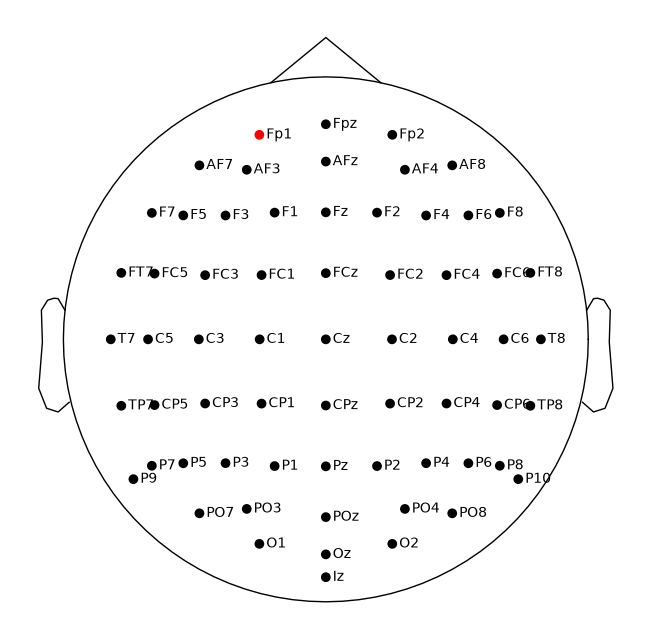

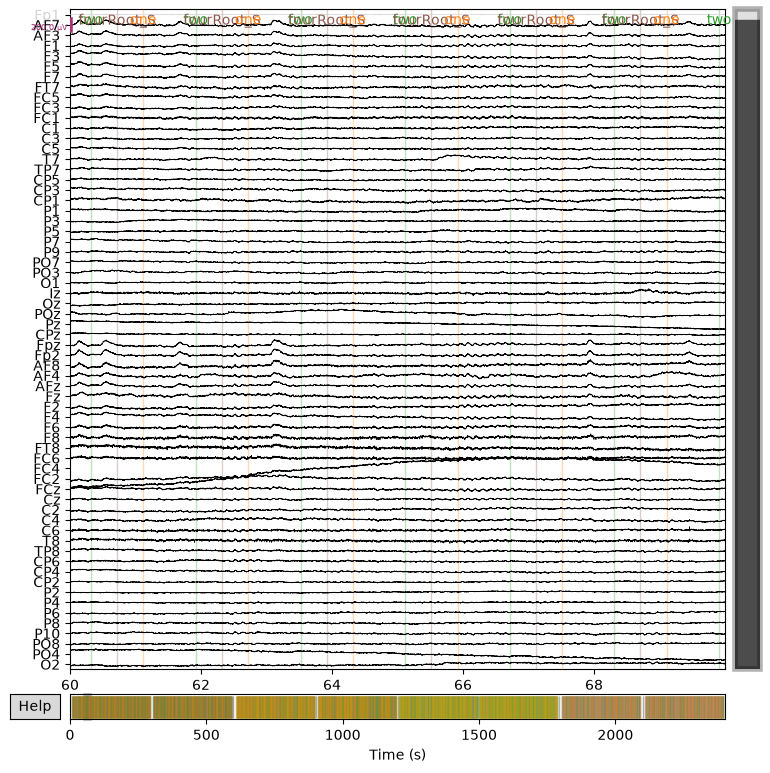

In [70]:
# Channels, sampling rate and length
print("Channels:", len(raw.ch_names), "| Sampling rate:", raw.info["sfreq"], "Hz",
      "| Length:", raw.n_times / raw.info["sfreq"], "s (eeg.json:", eeg_json_report.loc[participant, "RecordingDuration"], "s)")

# Bad channels
print("Bad channels:", raw.info["bads"])

# MNE's annotations should have the same codes and times as events.tsv
e = events[participant]
print("Events match events.tsv:", list(raw.annotations.description) == list(e["value"].astype(str))
      and np.allclose(raw.annotations.onset, e["onset"]))
print("Boundary events:", (raw.annotations.description == "boundary").sum())

# Electrode positions (bad channels in red)
raw.plot_sensors(show_names=True)

# 10 seconds of EEG on every channel, on a 100 µV scale
raw.plot(start=60, duration=10, n_channels=64, scalings=dict(eeg=100e-6));

**Result:**
- sub-002 loads with 64 channels at 2048 Hz for its full 2,402 s, with Fp1 marked bad. All 4,583 events, including the 7 `boundary` events, match `events.tsv`.
- The front channels show large bumps every few seconds, probably eye blinks. These can be removed later with ICA. The slow drift in some channels is removed by filtering (step 5).

### Step 4: Downsample to 256 samples per second

The EEG was recorded at 2048 samples per second, far more than needed: the brain responses we study are below about 40 Hz, and 256 samples per second keeps everything up to 128 Hz. Keeping 1 sample in 8 makes the recording 8 times smaller, so every later step runs faster.

Downsampling smooths the signal slightly, and the 7 joins between blocks are sudden jumps. MNE's `polyphase` method keeps the effect of each jump within 0.05 s of the join (no trial is that close to one), while the default method spreads small errors (1–3 µV) for more than 30 s around each join.

The check cell reports:
- the new sampling rate and number of samples (should be 256 Hz and 8 times fewer samples)
- whether the middle-chord times still match the trial table
- the largest gap between a middle chord and the nearest sample (samples are now 3.9 ms apart, so this should be under 2 ms)

In [74]:
# Keep 256 samples per second
raw.resample(256, method="polyphase")

<RawEEGLAB | sub-002_task-AuditoryOddballChords_eeg.fdt, 64 x 614912 (2402.0 s), ~300.3 MiB, data loaded>

In [75]:
# New sampling rate and number of samples
print("Sampling rate:", raw.info["sfreq"], "Hz | Samples:", raw.n_times,
      "(before:", fdt_report.loc[participant, "n_samples"], ")")

# Event times are kept in seconds, so the middle chords should still match the trial table
middle_onsets = trials.loc[trials["participant"] == participant, "onset_s"].to_numpy()
annotation_onsets = raw.annotations.onset[np.isin(raw.annotations.description, trials["code"])]
print("Middle chords match trial table:", np.allclose(annotation_onsets, middle_onsets))

# Largest gap between a middle chord and the nearest sample, in ms
samples = middle_onsets * raw.info["sfreq"]
print("Largest gap to nearest sample:", round(np.abs(samples - samples.round()).max() / raw.info["sfreq"] * 1000, 2), "ms")

Sampling rate: 256.0 Hz | Samples: 614912 (before: 4919296 )
Middle chords match trial table: True
Largest gap to nearest sample: 1.95 ms


**Result:** sub-002 now has 256 samples per second (614,912 samples instead of 4,919,296), and takes about 300 MB of memory instead of 2.4 GB. The middle-chord times still match the trial table, and each is within 1.95 ms of a sample.

### Log: milestone checks

What each step found and decided, for the report and slides.

| Step | Check | Found | Decision and why |
|---|---|---|---|
| 1 | Missing data | 10 recordings are 1–8% recorded; sub-001 and sub-030 are 92%. | Exclude the 10: 0–15 deviants each is too few to test on, and imputing from other participants would invent data and leak it between training and test participants; keep the 2 partial ones with only their recorded trials, giving 30 participants. |
| 1 | Missing data pattern | All 10 excluded are `Cl` women or `Imp` men. | Note as a limitation: group and gender stay linked. |
| 1 | Unusual values | Only age outlier (42) is an excluded participant. | No action needed. |
| 2 | Class imbalance | Each participant has 1,220 standard (84.7%), 109 exemplar (7.6%) and 111 function (7.7%) trials. | Note now: use balanced accuracy or AUC and compare with an "always standard" baseline; consider class weights. |
| 2 | Missing data | 113 trials of sub-001 and 109 of sub-030 fall after their recording ends. | Keep the rows with `recorded` = false so the table has every event; leave them out of EEG analysis. |
| 2 | Unusual values | Every middle chord is exactly 0.4 s after the first chord; trials within a block are 1.57–1.78 s apart. No timing errors. | No action needed. |
| 2 | Information leakage | `correct` is scored from a button press after the chord. `block`, `trial` and `onset_s` reveal the condition, because every participant heard the same trial order. | Kept for checking and grouping only, never as model features. |
| 3 | Unusual values | Channels stuck at the recording limit hold no EEG (Fp1 for sub-002); channel `Afz` is misspelled. | Mark stuck channels as bad so later steps leave them out; rename `Afz` to `AFz`. |
| 3 | Missing data | MNE can't load sub-001 and sub-030 as they are, because their files stop early. | Cut each recording at its last recorded sample before loading. |